In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [11]:
def haar_rows(img):
    a = img[:, 0::2]
    b = img[:, 1::2]
    approx = (a + b) / 2
    detail = (a - b) / 2
    return np.concatenate([approx, detail], axis=1)

def haar_2d(img):
    rows = haar_rows(img)
    return haar_rows(rows.T).T

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

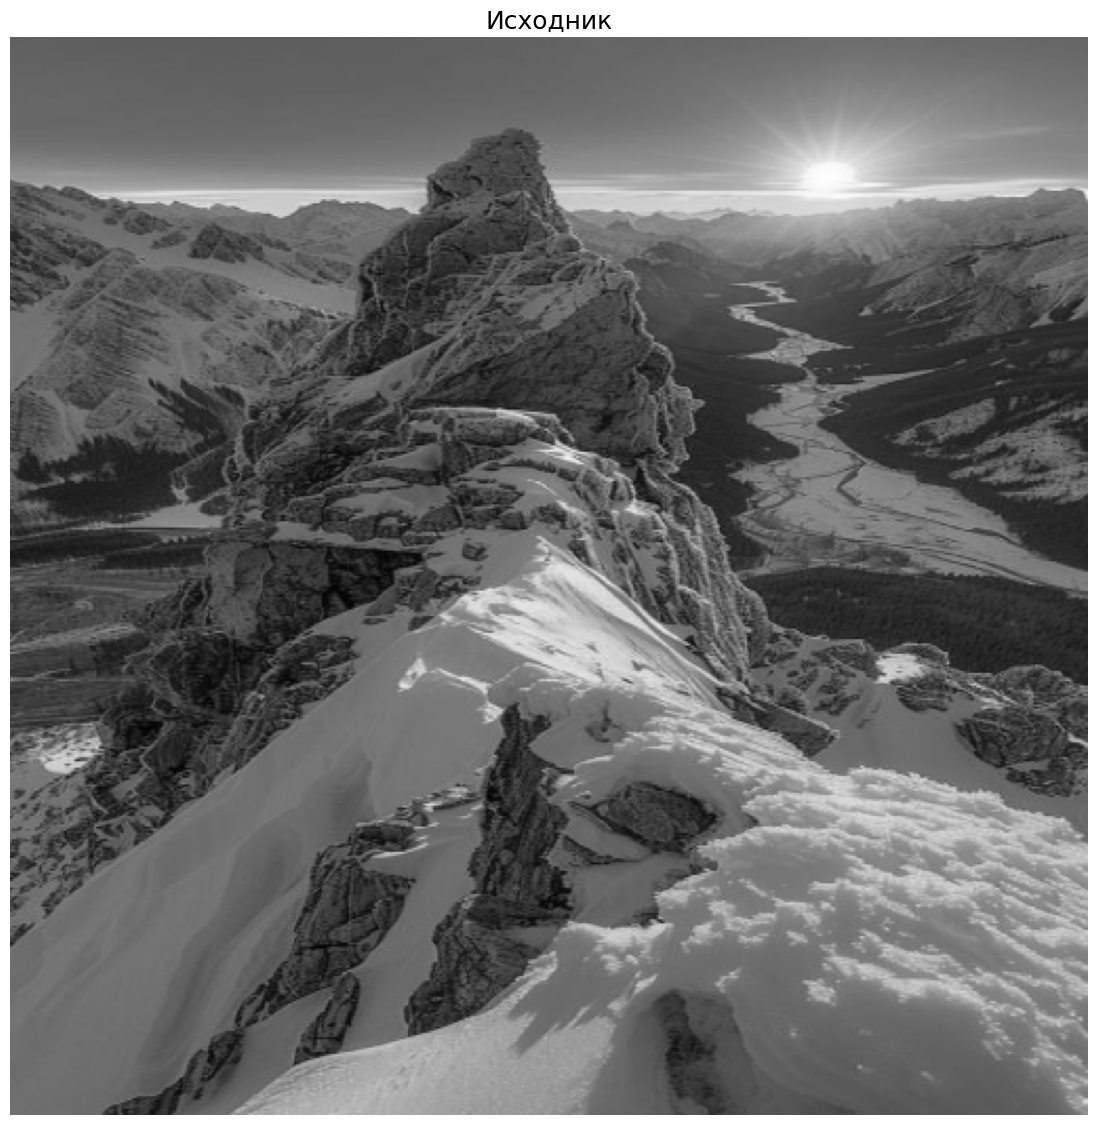

In [12]:
img = cv2.imread("Gori.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Не найдено изображение Gori.jpg.")
img = cv2.resize(img, (512, 512), interpolation=cv2.INTER_AREA)
img = img.astype(np.float64)
plt.figure(figsize=(14, 14))
plt.imshow(img, cmap="gray")
plt.title("Исходник", fontsize=18)
plt.axis("off")

In [13]:
lvl1 = haar_2d(img)
lvl2 = lvl1.copy()
lvl2[:256, :256] = haar_2d(lvl1[:256, :256])
lvl3 = lvl2.copy()
lvl3[:128, :128] = haar_2d(lvl2[:128, :128])

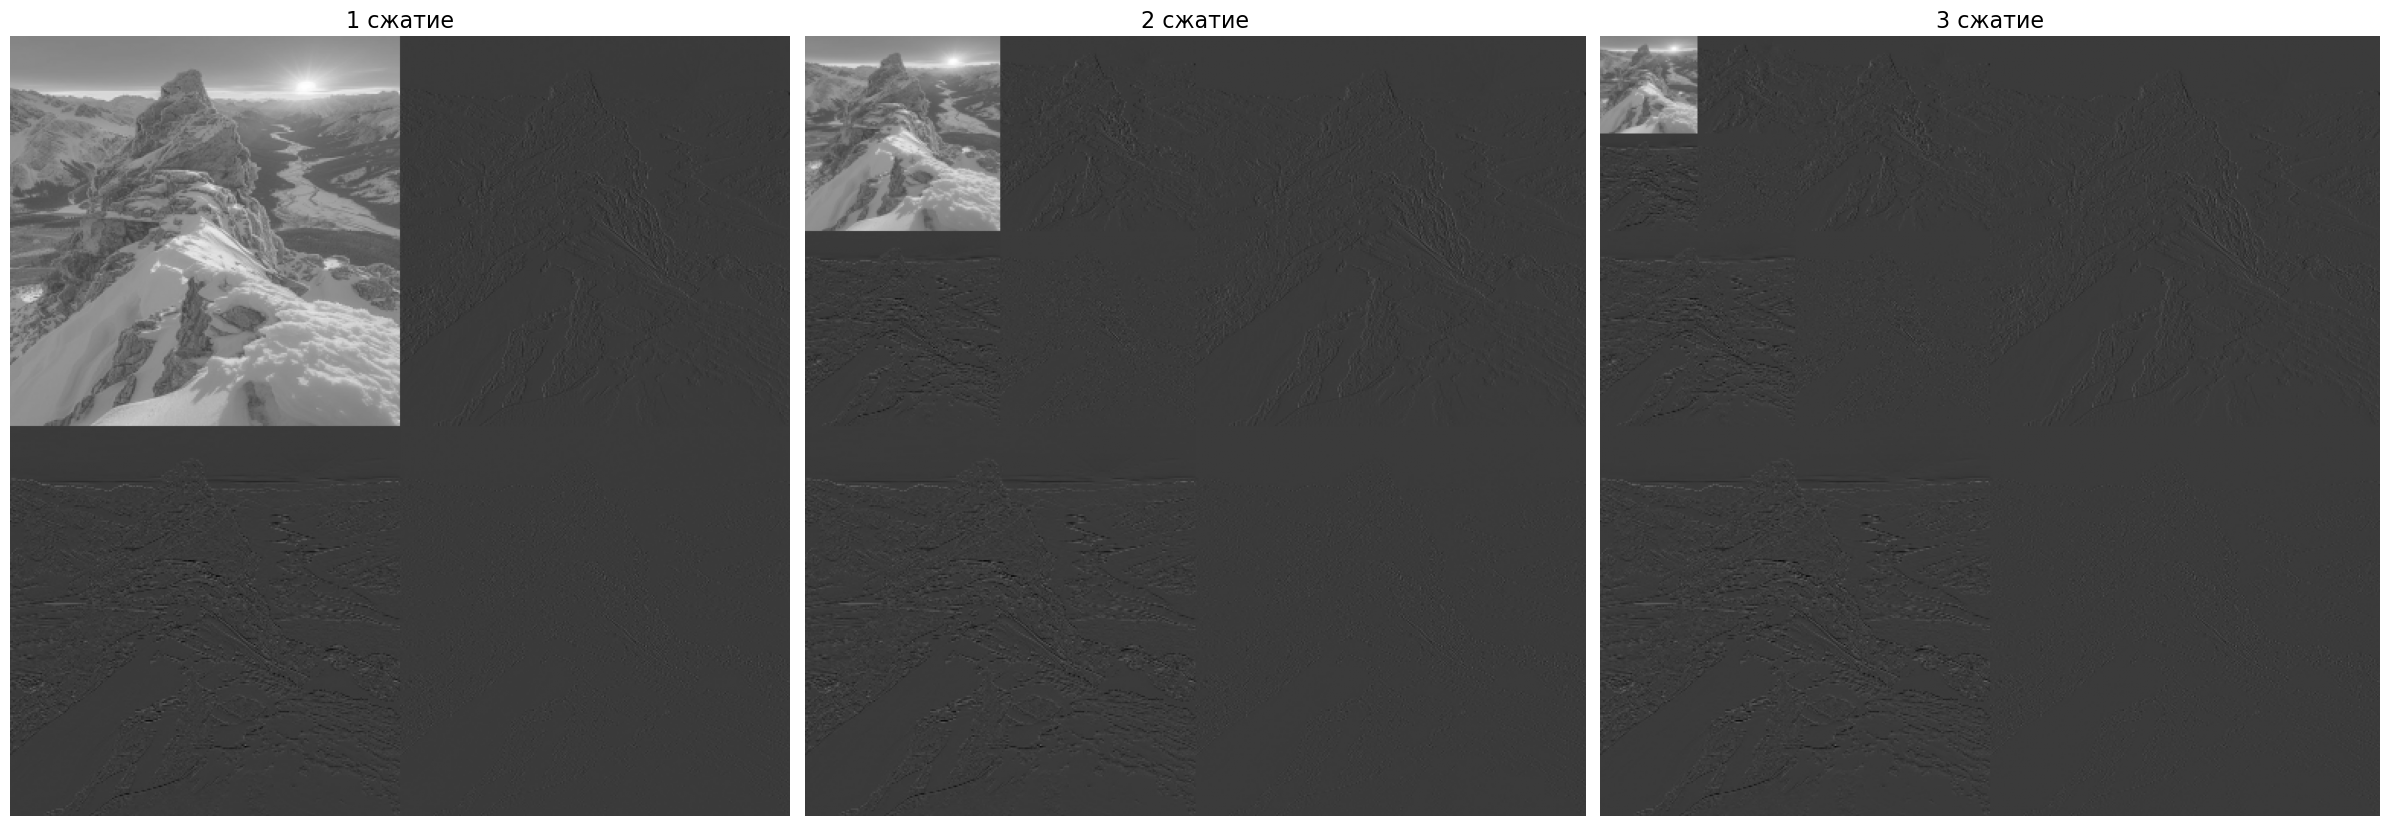

In [14]:
plt.figure(figsize=(24, 9))
plt.subplot(131), plt.imshow(lvl1, cmap="gray"), plt.title("1 сжатие", fontsize=16), plt.axis("off")
plt.subplot(132), plt.imshow(lvl2, cmap="gray"), plt.title("2 сжатие", fontsize=16), plt.axis("off")
plt.subplot(133), plt.imshow(lvl3, cmap="gray"), plt.title("3 сжатие", fontsize=16), plt.axis("off")
plt.tight_layout()
plt.show()

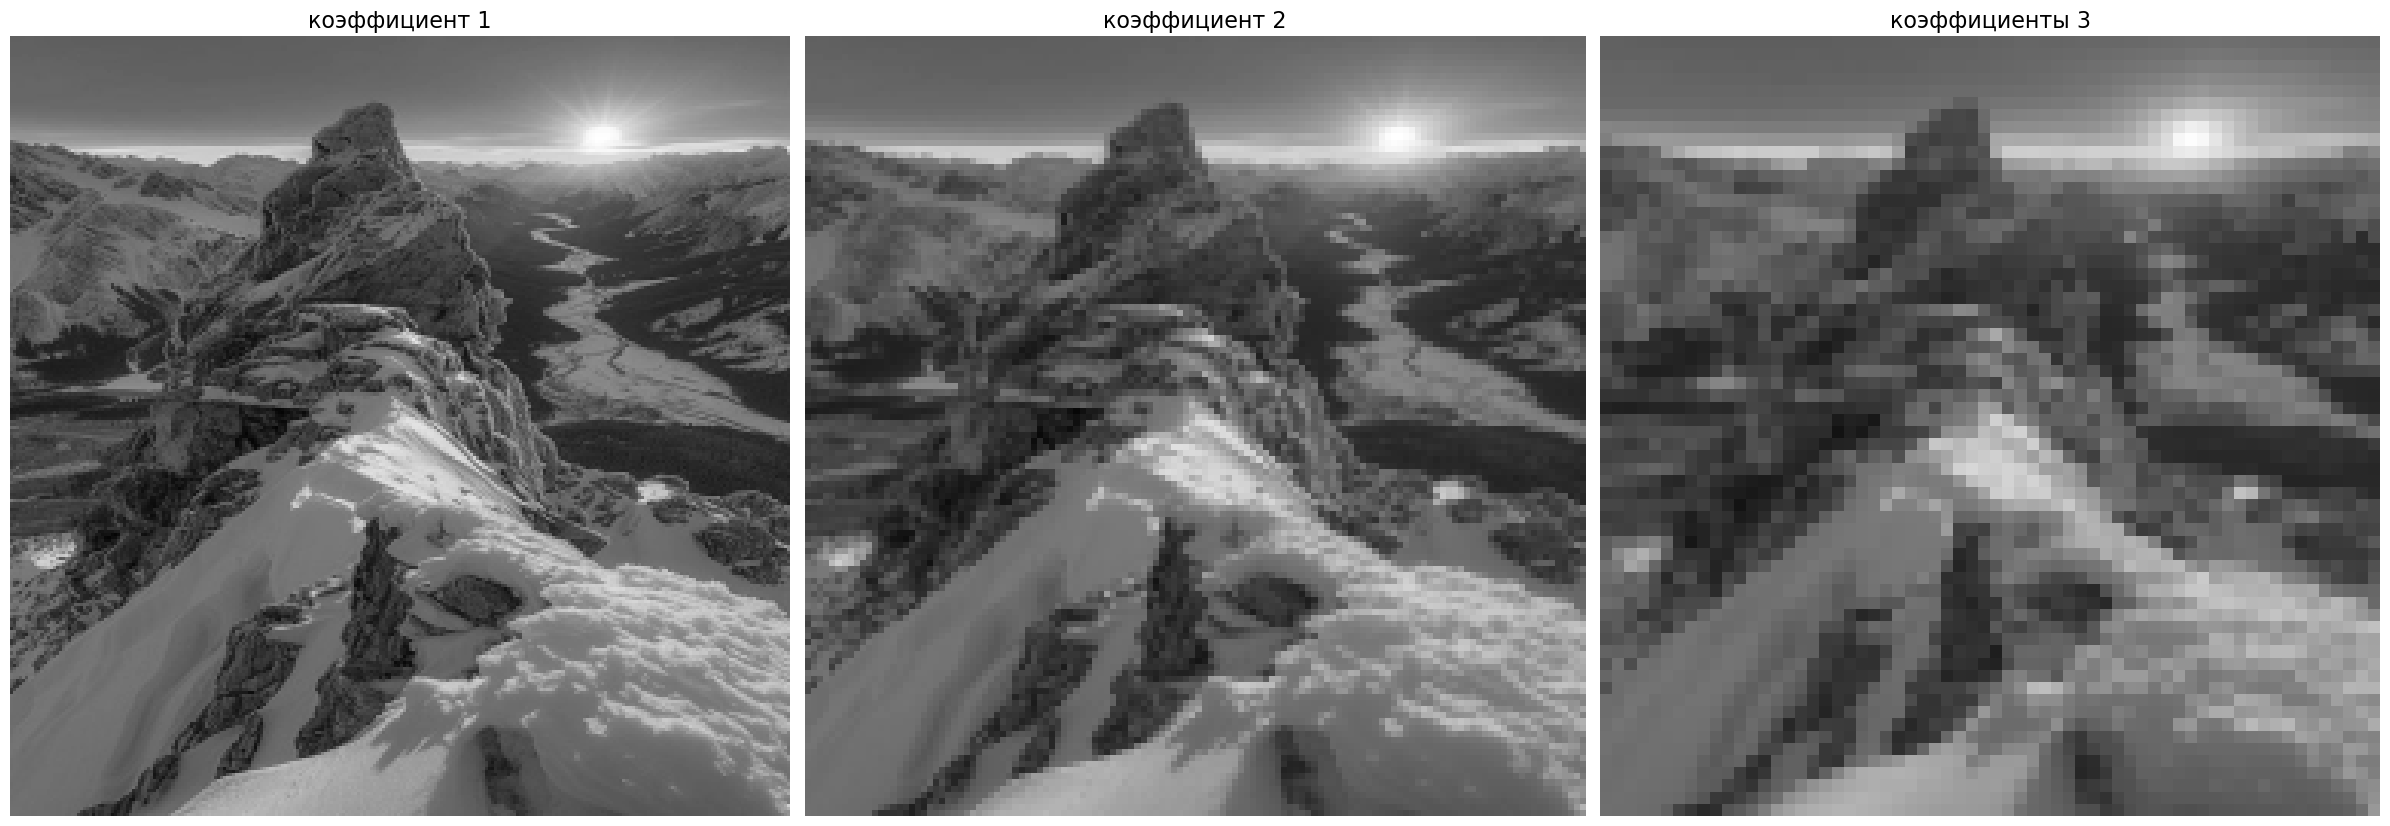

In [15]:
plt.figure(figsize=(24, 9))
plt.subplot(131), plt.imshow(lvl1[:256, :256], cmap="gray", vmin=0, vmax=255), plt.title("коэффициент 1", fontsize=16), plt.axis("off")
plt.subplot(132), plt.imshow(lvl2[:128, :128], cmap="gray", vmin=0, vmax=255), plt.title("коэффициент 2", fontsize=16), plt.axis("off")
plt.subplot(133), plt.imshow(lvl3[:64, :64], cmap="gray", vmin=0, vmax=255), plt.title("коэффициенты 3", fontsize=16), plt.axis("off")
plt.tight_layout()
plt.show()